# Modularity on the Karate Club Graph

**Course:** DSC212 – Graph Theory  
**Assignment:** Recursive spectral modularity partitioning

## Aim

The aim is to divide the Karate Club network into communities using the modularity matrix and its leading eigenvector. After each accepted split, I calculate degree centrality, betweenness centrality, closeness centrality and the clustering coefficient.

The community detection code uses the matrix definition and sign-based split described in the assignment handout. The `club` labels stored in the NetworkX dataset are not used to find the communities.

## 1. Imports and graph

NetworkX provides the Karate Club graph. The graph has 34 nodes and 78 edges. I keep the node order fixed so that rows and columns of the adjacency and modularity matrices always refer to the same nodes.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print("Number of nodes:", n)
print("Number of edges:", m)
print("Is the graph undirected?", not G.is_directed())

# A fixed layout makes the community plots comparable.
pos = nx.spring_layout(G, seed=42)

Number of nodes: 34
Number of edges: 78
Is the graph undirected? True


## 2. Modularity matrix

For an undirected graph, the assignment defines

\[
B = A - \frac{kk^T}{2m},
\]

where `A` is the binary adjacency matrix, `k` is the degree vector and `m` is the number of edges. I set `weight=None` when creating `A`, because the handout defines its entries as 0 or 1. The matrix is symmetric, so I use `numpy.linalg.eigh` to calculate its eigenvalues and eigenvectors.

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None, dtype=float)
k = np.array([G.degree(v) for v in nodes], dtype=float)
B = A - np.outer(k, k) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)
print("Maximum symmetry error:", np.max(np.abs(B - B.T)))

Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Maximum symmetry error: 0.0


## 3. Recursive spectral partitioning

For a current community `C`, I take the rows and columns of the original `B` corresponding to the nodes in `C`. I then find the eigenvector for the largest eigenvalue and assign nodes according to its sign:

- positive entry → first group;
- zero or negative entry → second group.

If the largest eigenvalue is nonpositive, the handout says to stop. I also check that both sign groups are non-empty. If every entry has the same sign, the prescribed sign rule does not produce a split, so I stop that branch rather than making an arbitrary cut.

In [3]:
node_to_index = {node: i for i, node in enumerate(nodes)}

# Each item in history stores the current partition after a split.
history = []
split_checks = []

def save_partition(communities):
    """Save a copy of the current partition."""
    ordered = [sorted(list(c)) for c in communities]
    ordered.sort(key=lambda c: c[0])
    history.append(ordered)


def try_split(community, communities):
    """Try to split one community using the leading eigenvector."""
    community = sorted(community)
    indices = [node_to_index[v] for v in community]
    B_C = B[np.ix_(indices, indices)]

    eigenvalues, eigenvectors = np.linalg.eigh(B_C)
    leading_value = float(eigenvalues[-1])
    leading_vector = eigenvectors[:, -1]

    group_positive = [v for v, x in zip(community, leading_vector) if x > 0]
    group_nonpositive = [v for v, x in zip(community, leading_vector) if x <= 0]

    check = {
        "community_size": len(community),
        "leading_eigenvalue": leading_value,
        "positive_side_size": len(group_positive),
        "nonpositive_side_size": len(group_nonpositive),
    }

    if leading_value <= 1e-10:
        check["result"] = "stopped: leading eigenvalue is nonpositive"
        split_checks.append(check)
        return

    if len(group_positive) == 0 or len(group_nonpositive) == 0:
        check["result"] = "stopped: sign rule produced an empty group"
        split_checks.append(check)
        return

    check["result"] = "split"
    split_checks.append(check)

    # Replace the parent community with its two children.
    parent_index = next(i for i, c in enumerate(communities) if set(c) == set(community))
    updated = communities[:parent_index] + [group_positive, group_nonpositive] + communities[parent_index + 1:]
    updated = [sorted(c) for c in updated]
    updated.sort(key=lambda c: c[0])
    communities[:] = updated
    save_partition(communities)

    # Continue recursively on both new communities.
    try_split(group_positive, communities)
    try_split(group_nonpositive, communities)


communities = [nodes.copy()]
save_partition(communities)  # Iteration 0: the full graph
try_split(nodes, communities)

print("Number of actual splits:", len(history) - 1)
print("Final number of communities:", len(communities))

checks_df = pd.DataFrame(split_checks)
display(checks_df)

for i, community in enumerate(communities, start=1):
    print(f"Community {i} ({len(community)} nodes):", community)

Number of actual splits: 4
Final number of communities: 5


,community_size,leading_eigenvalue,positive_side_size,nonpositive_side_size,result
0,34,4.977080,16,18,split
1,16,2.944129,10,6,split
2,10,2.571158,10,0,stopped: sign rule produced an empty group
3,6,2.147993,1,5,split
4,1,-0.006410,1,0,stopped: leading eigenvalue is nonpositive
5,5,2.147005,5,0,stopped: sign rule produced an empty group
6,18,2.504088,5,13,split
7,5,1.875925,0,5,stopped: sign rule produced an empty group
8,13,2.356350,0,13,stopped: sign rule produced an empty group


Community 1 (10 nodes): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2 (5 nodes): [4, 5, 6, 10, 16]
Community 3 (13 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4 (1 nodes): [11]
Community 5 (5 nodes): [24, 25, 27, 28, 31]


In [4]:
# Modularity of the final multi-community partition.
# Q = (1 / 2m) * sum(B_ij for pairs that belong to the same community)
final_modularity = nx.community.modularity(G, communities, weight=None)
community_label = {node: i for i, community in enumerate(communities) for node in community}
q_from_matrix = sum(
    B[i, j]
    for i, node_i in enumerate(nodes)
    for j, node_j in enumerate(nodes)
    if community_label[node_i] == community_label[node_j]
) / (2 * m)

print("Modularity of the final partition:", round(final_modularity, 4))
print("Modularity calculated from B:", round(float(q_from_matrix), 4))
assert np.isclose(final_modularity, q_from_matrix)

Modularity of the final partition: 0.4094
Modularity calculated from B: 0.4094


## 4. Graph after each split

The same spring-layout coordinates are used in every figure. Only the node colours change, so the changes in community membership can be compared without the layout moving around.

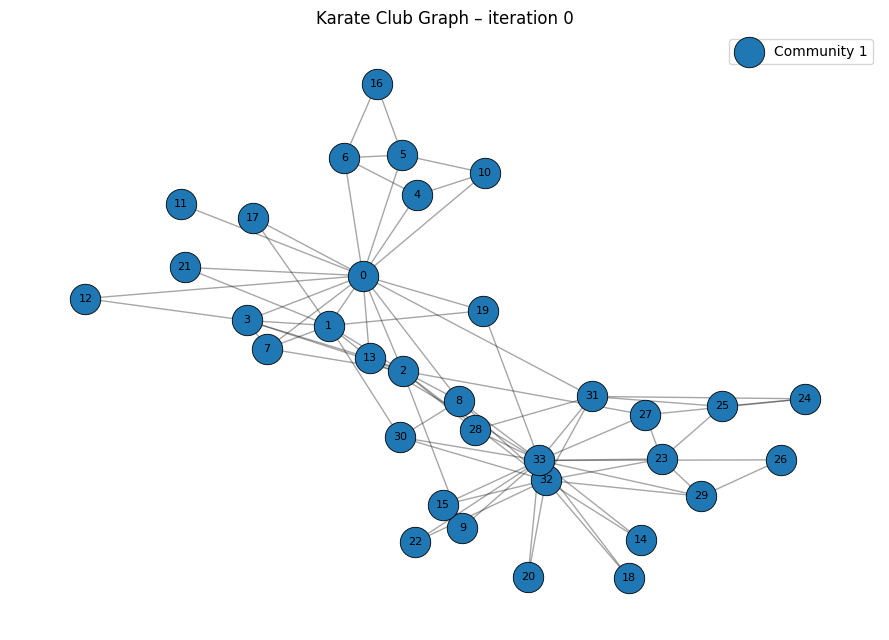

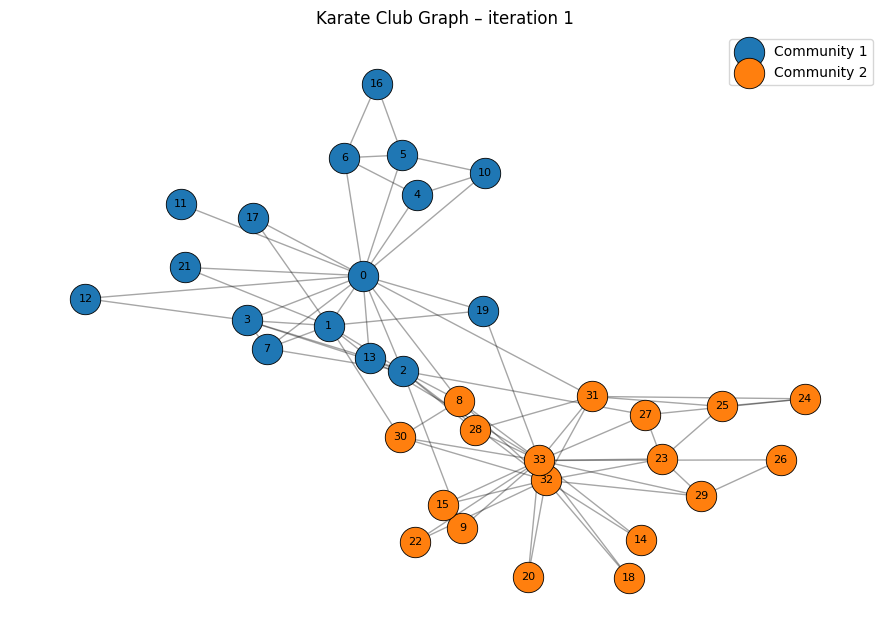

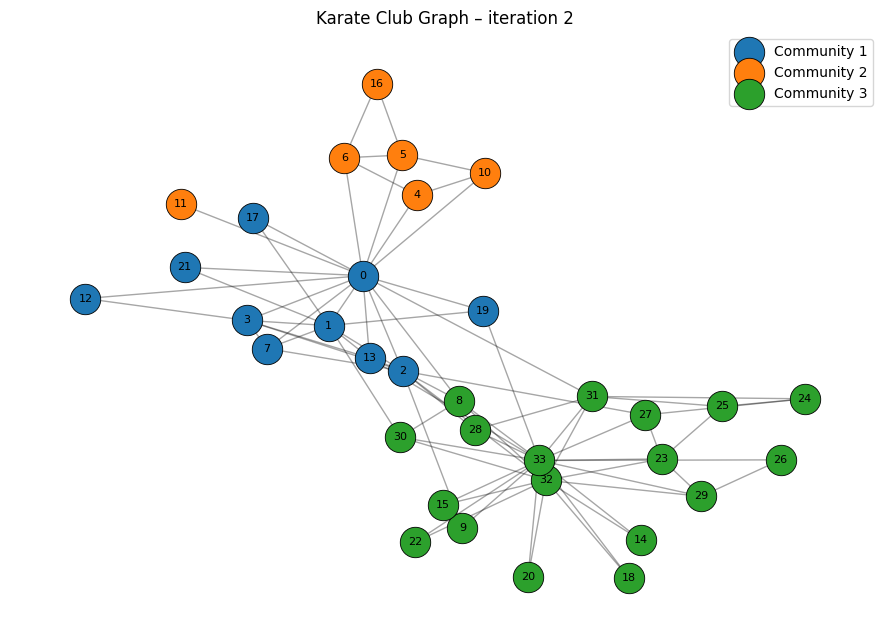

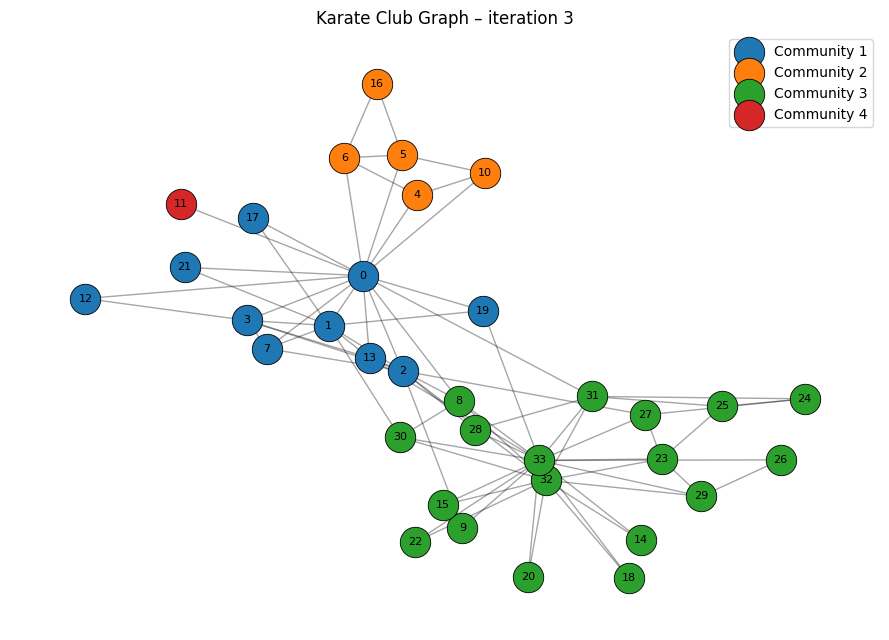

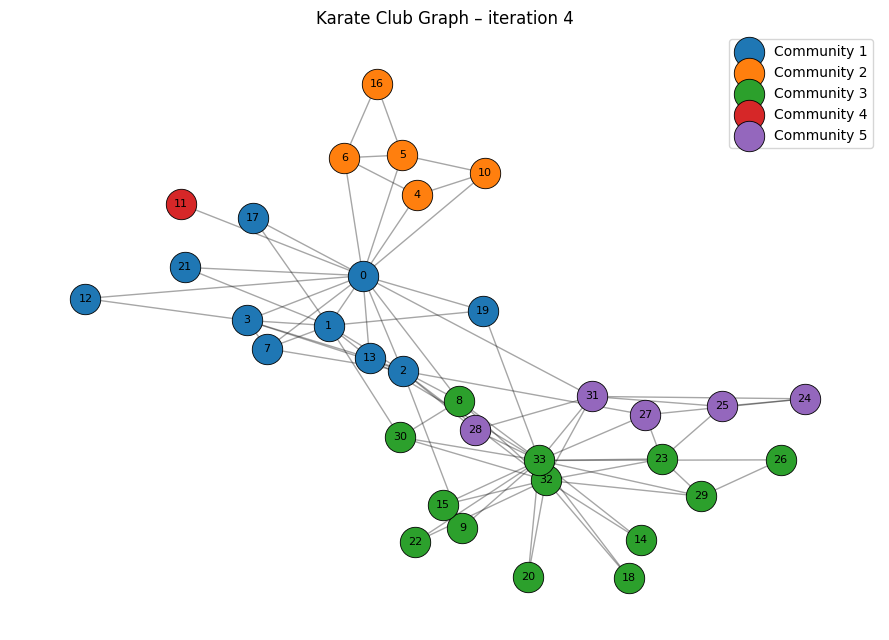

In [5]:
# Give each final community a consistent colour.
colour_map = plt.get_cmap("tab10")
final_community_of = {}
for community_id, community in enumerate(communities):
    for node in community:
        final_community_of[node] = community_id


def draw_partition(partition, iteration):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0, ax=ax)

    for community_id, community in enumerate(partition):
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=community,
            node_color=[colour_map(community_id % 10)],
            node_size=480,
            edgecolors="black",
            linewidths=0.6,
            ax=ax,
            label=f"Community {community_id + 1}"
        )

    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(f"Karate Club Graph – iteration {iteration}")
    ax.legend(loc="best", frameon=True)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"figures/community_iteration_{iteration:02d}.png", dpi=180, bbox_inches="tight")
    plt.show()


for iteration, partition in enumerate(history):
    draw_partition(partition, iteration)

## 5. Node metrics after each split

To make the values change as the partition changes, I calculate each node's metrics inside the induced subgraph of its current community. For example, after a split, a node's degree centrality is calculated using only its neighbours that remain in the same community.

This is different from recalculating metrics on the unchanged full graph: metrics on the full graph would be identical at every iteration. NetworkX's built-in functions are used for all four measures.

In [6]:
metric_functions = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

metric_history = []

for partition in history:
    values_for_iteration = {name: {} for name in metric_functions}

    for community in partition:
        H = G.subgraph(community).copy()
        for metric_name, metric_function in metric_functions.items():
            values = metric_function(H)
            values_for_iteration[metric_name].update(values)

    metric_history.append(values_for_iteration)

# The full-graph values are also kept as a reference.
full_graph_metrics = {
    metric_name: metric_function(G)
    for metric_name, metric_function in metric_functions.items()
}

print("Metric values stored for", len(metric_history), "iterations.")
print("Nodes in the first iteration:", len(metric_history[0]["Degree centrality"]))

Metric values stored for 5 iterations.
Nodes in the first iteration: 34


## 6. Plot metric evolution for every node

The heatmap has one row per node and one column per partition stage. Rows are grouped by final community, and the colour bar gives the metric value. This keeps all node IDs readable.

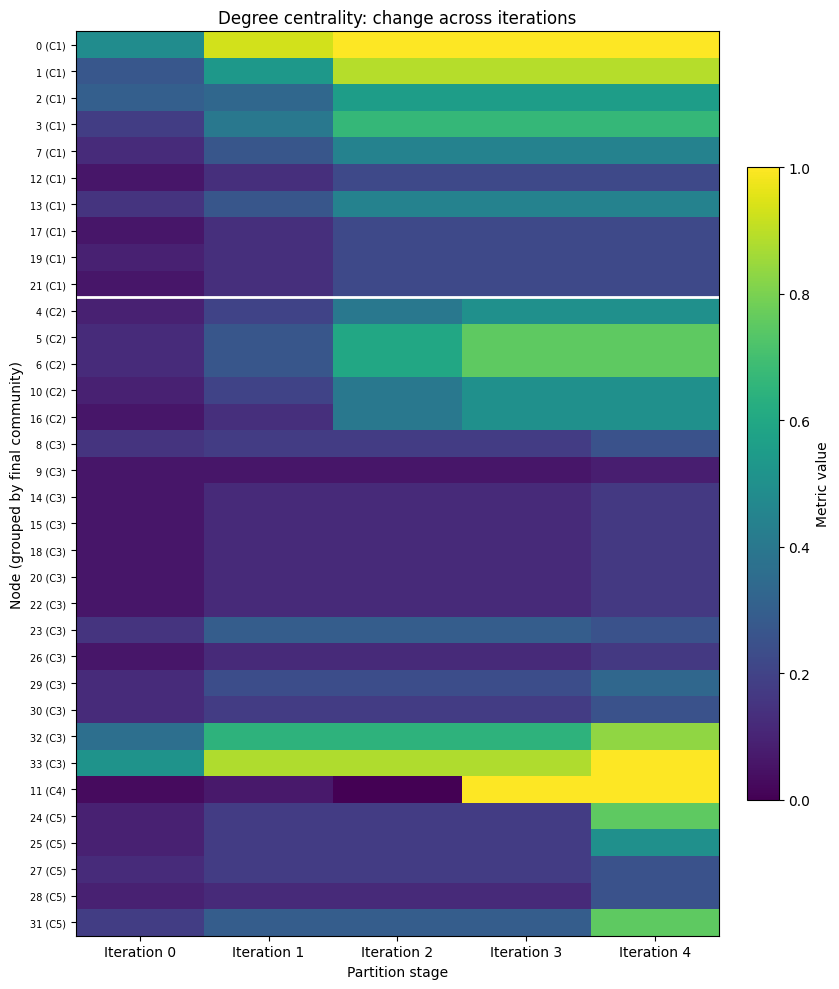

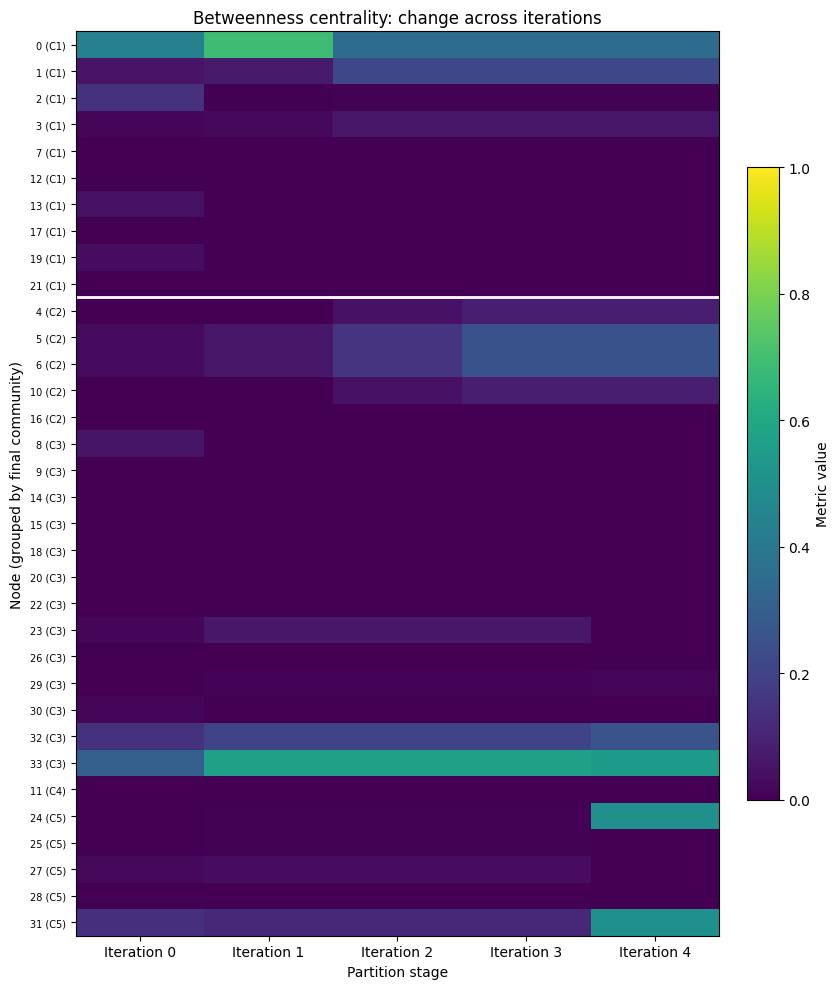

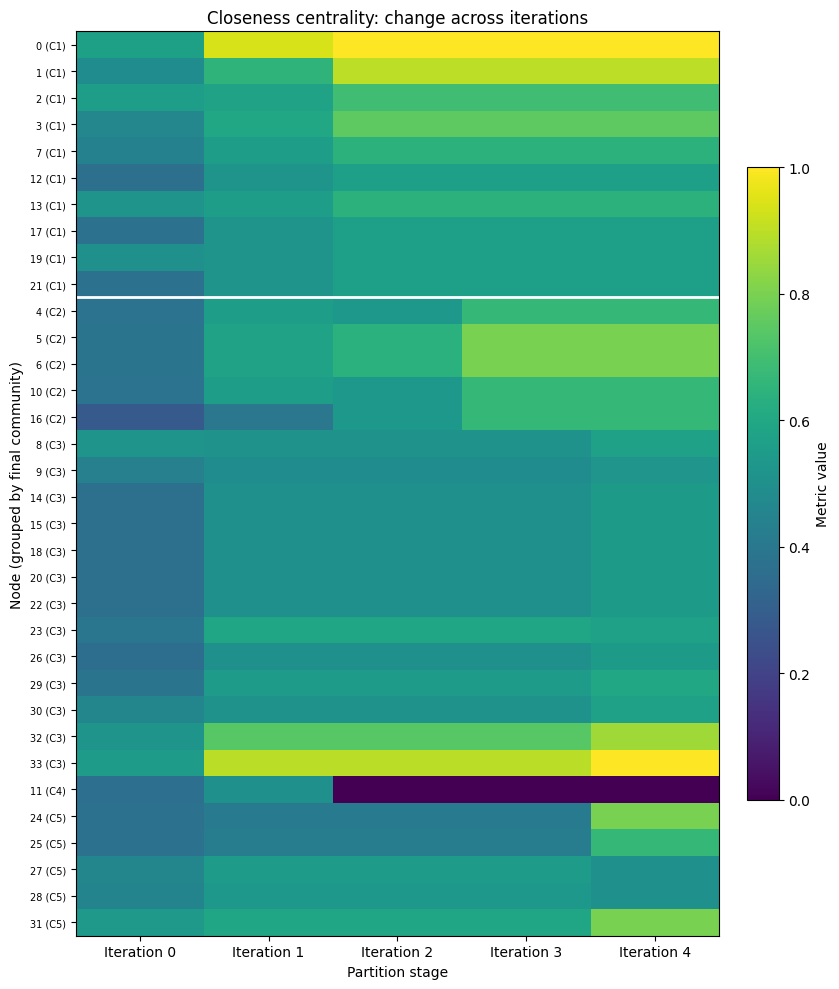

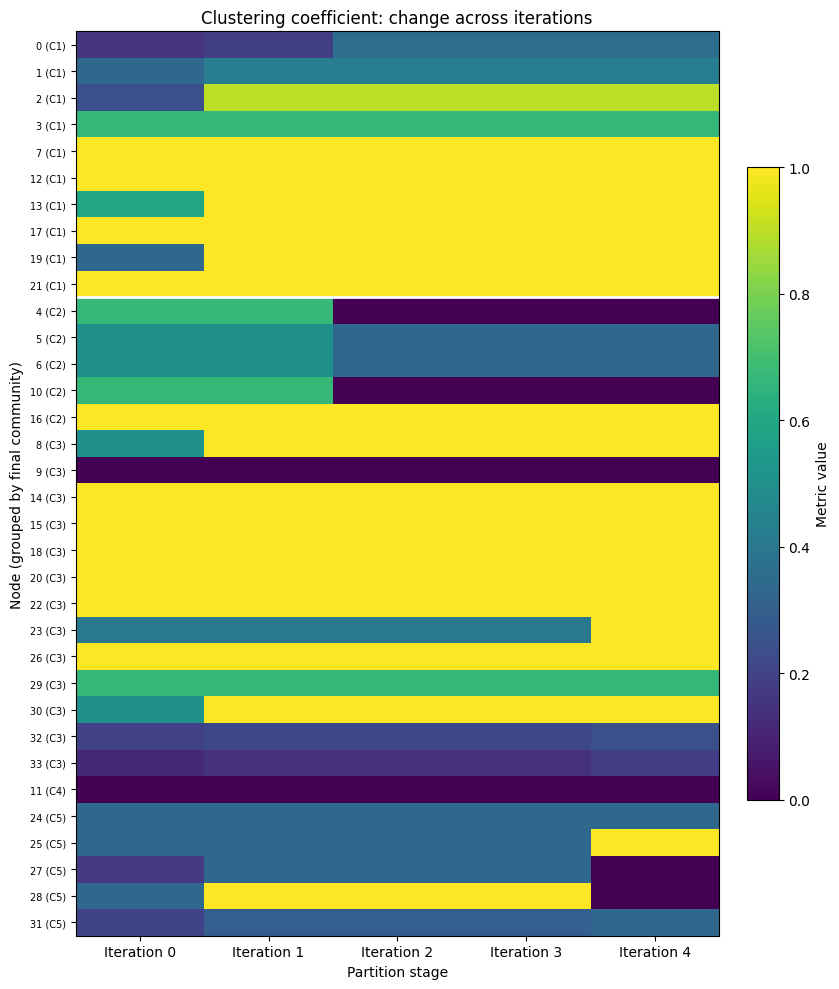

In [7]:
metric_names = list(metric_functions.keys())
iteration_labels = [f"Iteration {i}" for i in range(len(history))]
plot_order = [node for community in communities for node in sorted(community)]

for metric_name in metric_names:
    values = np.array([
        [metric_history[iteration][metric_name][node] for iteration in range(len(history))]
        for node in plot_order
    ])

    fig, ax = plt.subplots(figsize=(8.5, 10))
    image = ax.imshow(values, aspect="auto", interpolation="nearest",
                       cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{metric_name}: change across iterations")
    ax.set_xlabel("Partition stage")
    ax.set_ylabel("Node (grouped by final community)")
    ax.set_xticks(np.arange(len(history)), iteration_labels)
    ax.set_yticks(np.arange(len(plot_order)),
                   [f"{node} (C{final_community_of[node] + 1})" for node in plot_order],
                   fontsize=7)

    # Separate the rows belonging to the two final communities.
    if len(communities) > 1:
        ax.axhline(len(communities[0]) - 0.5, color="white", linewidth=2)

    fig.colorbar(image, ax=ax, label="Metric value", fraction=0.045, pad=0.04)
    fig.tight_layout()
    safe_name = metric_name.lower().replace(" ", "_")
    fig.savefig(f"figures/{safe_name}_evolution.png", dpi=180, bbox_inches="tight")
    plt.show()

## 7. Central nodes and a short discussion

The following tables show the five highest-scoring nodes for each measure in the original graph and inside the final communities. The centrality values inside a community are calculated on that community's induced subgraph, so they should not be interpreted as exactly the same quantity as a full-graph score.

In [8]:
def top_nodes(values, count=5):
    return sorted(values.items(), key=lambda item: (-item[1], item[0]))[:count]

print("Top nodes in the original graph")
for metric_name, values in full_graph_metrics.items():
    print("\\n" + metric_name)
    display(pd.DataFrame(top_nodes(values), columns=["Node", "Value"]))

print("Top nodes inside each final community")
for community_id, community in enumerate(communities, start=1):
    print(f"\\nCommunity {community_id}")
    for metric_name in metric_names:
        values = {node: metric_history[-1][metric_name][node] for node in community}
        print(metric_name)
        display(pd.DataFrame(top_nodes(values), columns=["Node", "Value"]))

Top nodes in the original graph
\nDegree centrality


,Node,Value
0,33,0.515152
1,0,0.484848
2,32,0.363636
3,2,0.303030
4,1,0.272727


\nBetweenness centrality


,Node,Value
0,0,0.437635
1,33,0.304075
2,32,0.145247
3,2,0.143657
4,31,0.138276


\nCloseness centrality


,Node,Value
0,0,0.568966
1,2,0.559322
2,33,0.550000
3,31,0.540984
4,8,0.515625


... (38 outputs left out)

Closeness centrality


,Node,Value
0,24,0.800000
1,31,0.800000
2,25,0.666667
3,27,0.500000
4,28,0.500000


Clustering coefficient


,Node,Value
0,25,1.000000
1,24,0.333333
2,31,0.333333
3,27,0.000000
4,28,0.000000


### Discussion

In the original graph, node 33 has the highest degree centrality (0.515), while node 0 has the highest betweenness (0.438) and closeness (0.569). Node 33 has the most direct links, while node 0 lies on many shortest paths between other nodes.

The final partition has five communities of sizes 10, 5, 13, 1 and 5, and its modularity is 0.4094. Node 0 remains the most central node in the 10-node community: its degree and closeness centralities are both 1.0, and its betweenness is 0.354. Node 33 is the leading node in the 13-node community, with degree and closeness centralities of 1.0 and betweenness of 0.545. Their roles as central nodes therefore remain visible after the network is divided. One group contains only node 11; it was produced by a sign split of a six-node group, not added manually.

The clustering coefficient gives a different view. Several nodes in the 10-node and 13-node communities have a coefficient of 1.0 because all of their neighbours are connected to one another. A node can therefore be strongly embedded in a local group without being the most important bridge in the full graph.

The values after a split are calculated on smaller induced subgraphs. The set of paths and the normalising factors change, so an increase in a node's metric does not mean that the original graph itself changed. It means that the node is central relative to the members of its own community.

## 8. Implementation note

For some candidate groups, the leading eigenvalue is positive but the corresponding eigenvector has entries of only one sign. The sign-thresholding rule then produces an empty side. The code records this case and stops that branch. It does not force another split using a different threshold, because that would change the procedure specified in the handout.

A standard recursive modularity formulation may use an adjusted submatrix or an additional threshold-selection step. That is a possible extension, but it should be kept separate from this implementation unless the instructor confirms that such a variant is expected.

## Reference

Newman, M. E. J. (2006). “Modularity and community structure in networks.” *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.